# 02 · Weather: Open-Meteo (archive + forecast)

Exploration only. Goal: understand format, history length, archive delay and whether archive and forecast share a schema.

- Archive: `https://archive-api.open-meteo.com/v1/archive`
- Forecast: `https://api.open-meteo.com/v1/forecast`

No key. Free for non-commercial use.

In [1]:
import json
import urllib.parse
import urllib.request
from datetime import date, timedelta

import pandas as pd

ARCHIVE = "https://archive-api.open-meteo.com/v1/archive"
FORECAST = "https://api.open-meteo.com/v1/forecast"
HOURLY = "temperature_2m,precipitation,wind_speed_10m,cloud_cover,shortwave_radiation"

# shortcut: one city per price area, revisit with several weighted points per area later
POINTS = {
    "NO1": ("Oslo", 59.91, 10.75),
    "NO2": ("Kristiansand", 58.15, 8.00),
    "NO3": ("Trondheim", 63.43, 10.39),
    "NO4": ("Tromsø", 69.65, 18.96),
    "NO5": ("Bergen", 60.39, 5.32),
}


def get(base, **params):
    url = f"{base}?{urllib.parse.urlencode(params, safe=',')}"
    with urllib.request.urlopen(url, timeout=30) as r:
        return json.load(r)


today = date.today()
_, lat, lon = POINTS["NO2"]

## 1. Raw format (archive)

In [2]:
raw = get(ARCHIVE, latitude=lat, longitude=lon, start_date=str(today - timedelta(days=10)),
          end_date=str(today - timedelta(days=9)), hourly=HOURLY)
{k: v for k, v in raw.items() if k != "hourly"}

{'latitude': 58.17223,
 'longitude': 8.074398,
 'generationtime_ms': 0.18584728240966797,
 'utc_offset_seconds': 0,
 'timezone': 'GMT',
 'timezone_abbreviation': 'GMT',
 'elevation': 5.0,
 'hourly_units': {'time': 'iso8601',
  'temperature_2m': '°C',
  'precipitation': 'mm',
  'wind_speed_10m': 'km/h',
  'cloud_cover': '%',
  'shortwave_radiation': 'W/m²'}}

In [3]:
df = pd.DataFrame(raw["hourly"])
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   time                 48 non-null     str    
 1   temperature_2m       48 non-null     float64
 2   precipitation        48 non-null     float64
 3   wind_speed_10m       48 non-null     float64
 4   cloud_cover          48 non-null     int64  
 5   shortwave_radiation  48 non-null     float64
dtypes: float64(4), int64(1), str(1)
memory usage: 2.4 KB


,time,temperature_2m,precipitation,wind_speed_10m,cloud_cover,shortwave_radiation
0,2026-10-10T00:00,7.4,1.0,23.5,84,0.0
1,2026-10-10T01:00,6.8,0.3,19.7,96,0.0
2,2026-10-10T02:00,6.3,0.8,21.1,100,0.0
3,2026-10-10T03:00,5.8,0.8,20.4,100,0.0
4,2026-10-10T04:00,5.8,0.1,17.3,100,0.0


Note: the returned latitude/longitude are snapped to the model grid, times are **UTC** (`timezone: GMT`) without an offset, and units are in `hourly_units` (wind is km/h).

## 2. How far back does the archive go?

In [4]:
old = get(ARCHIVE, latitude=lat, longitude=lon, start_date="1940-01-01", end_date="1940-01-01",
          hourly=HOURLY)
pd.DataFrame(old["hourly"]).head(3)

,time,temperature_2m,precipitation,wind_speed_10m,cloud_cover,shortwave_radiation
0,1940-01-01T00:00,-14.7,NaN,10.1,11,NaN
1,1940-01-01T01:00,-15.6,NaN,10.5,3,NaN
2,1940-01-01T02:00,-15.3,NaN,8.6,4,NaN


## 3. Archive delay: how recent is the latest non-null hour?

In [5]:
recent = get(ARCHIVE, latitude=lat, longitude=lon, start_date=str(today - timedelta(days=14)),
             end_date=str(today), hourly="temperature_2m")
s = pd.Series(recent["hourly"]["temperature_2m"], index=pd.to_datetime(recent["hourly"]["time"]))
last, now = s.last_valid_index(), pd.Timestamp.now("UTC").tz_localize(None)
print("Now (UTC):         ", now.floor("min"))
print("Last non-null hour:", last)
print("Archive reaches into the future:" if last > now else "Archive delay:", abs(now - last).round("h"))

Now (UTC):          2026-10-20 10:24:00
Last non-null hour: 2026-10-20 23:00:00
Archive reaches into the future: 0 days 13:00:00


If the archive reaches past *now*, recent days are not observations/reanalysis but filled from forecast models, and they may be revised later. To test: save a recent day today and fetch the same day again next week, then compare.

## 4. Forecast: same schema as the archive? How far ahead?

In [6]:
fc = get(FORECAST, latitude=lat, longitude=lon, hourly=HOURLY, forecast_days=16, past_days=2)
fdf = pd.DataFrame(fc["hourly"])
fdf["time"] = pd.to_datetime(fdf["time"])
print("Same columns as archive:", list(fdf.columns) == list(df.columns))
print("Same units as archive:", fc["hourly_units"] == raw["hourly_units"])
print("Range:", fdf["time"].min(), "→", fdf["time"].max(), f"({len(fdf)} hours)")
print("Nulls per column:")
print(fdf.isna().sum())
print("Hours with nulls:", fdf.loc[fdf.isna().any(axis=1), "time"].agg(["min", "max"]).tolist())

Same columns as archive: True
Same units as archive: True
Range: 2026-10-18 00:00:00 → 2026-11-04 23:00:00 (432 hours)
Nulls per column:
time                    0
temperature_2m         21
precipitation          23
wind_speed_10m         21
cloud_cover            21
shortwave_radiation    22
dtype: int64
Hours with nulls: [Timestamp('2026-11-04 01:00:00'), Timestamp('2026-11-04 23:00:00')]


## 5. All price-area points, last 30 days (archive)

In [7]:
frames = []
for area, (city, la, lo) in POINTS.items():
    r = get(ARCHIVE, latitude=la, longitude=lo, start_date=str(today - timedelta(days=37)),
            end_date=str(today - timedelta(days=7)), hourly=HOURLY)
    frames.append(pd.DataFrame(r["hourly"]).assign(area=area, city=city))
w = pd.concat(frames, ignore_index=True)
w["time"] = pd.to_datetime(w["time"])

cols = HOURLY.split(",")
print("Rows per area:", w.groupby("area").size().to_dict())
print("Duplicate (area, time):", w.duplicated(["area", "time"]).sum())
w.groupby("area")[cols].agg(["min", "mean", "max"]).round(1).T

Rows per area: {'NO1': 744, 'NO2': 744, 'NO3': 744, 'NO4': 744, 'NO5': 744}
Duplicate (area, time): 0


area                        NO1    NO2    NO3    NO4    NO5
temperature_2m      min     2.0    2.6    2.5   -3.3    2.6
                    mean   11.6   12.2    9.9    6.9   10.3
                    max    18.5   19.6   17.5   14.8   22.0
precipitation       min     0.0    0.0    0.0    0.0    0.0
                    mean    0.1    0.2    0.1    0.2    0.6
                    max     3.7    6.0    5.5    4.3    7.6
wind_speed_10m      min     0.2    0.6    0.0    0.2    0.2
                    mean   10.8   15.2   11.9    9.3   13.2
                    max    27.6   29.2   42.0   30.0   36.1
cloud_cover         min     0.0    0.0    0.0    0.0    0.0
                    mean   67.7   65.0   76.9   81.3   81.9
                    max   100.0  100.0  100.0  100.0  100.0
shortwave_radiation min     0.0    0.0    0.0    0.0    0.0
                    mean   80.4   88.0   64.8   44.2   65.2
                    max   539.0  555.0  438.0  364.0  465.0

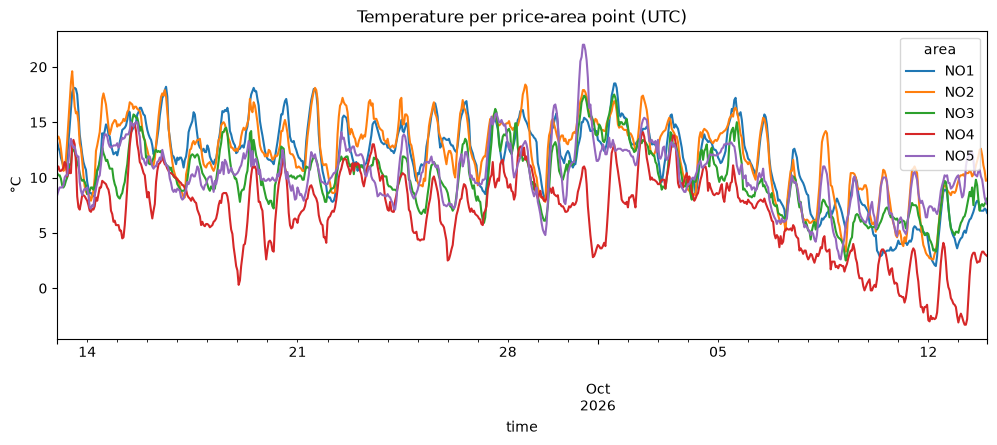

In [8]:
w.pivot_table(index="time", columns="area", values="temperature_2m").plot(
    figsize=(12, 4), ylabel="°C", title="Temperature per price-area point (UTC)"
);

## Findings

Summarised in `docs/data-sources.md`.

- **Archive starts:** 1940-01-01. Precipitation and shortwave radiation are null until 07:00 UTC on that first day.
- **Archive delay:** the archive already returns values about 14 hours into the future, so the most recent days are model-filled and may be revised. Ingestion therefore treats the archive as settled only after 5 days (the ERA5 delay in the Open-Meteo docs).
- **Forecast horizon:** `forecast_days` is at most 16. The cell above returns 432 hourly rows (16 days plus 2 `past_days`), and the last day is partly null.
- **Schema:** archive and forecast share columns and units. Times are UTC without an offset, coordinates snap to the model grid, wind is in km/h.
- **Quality (30-day sample, 5 points):** no nulls, no duplicates, 24 rows per day.
- **Open question:** one city per price area is a simplification. Several weighted points per area may represent demand and inflow better.